In [13]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


Анализ зарплат в Data Science 2021-2023

## График 1. Медианная зарплата по должностям

**Что визуализировано:** медианная зарплата (`salary_in_usd`) для топ-10
самых частых должностей. Горизонтальный столбчатый график, отсортирован
по возрастанию; взята медиана, а не среднее, чтобы снизить влияние выбросов.



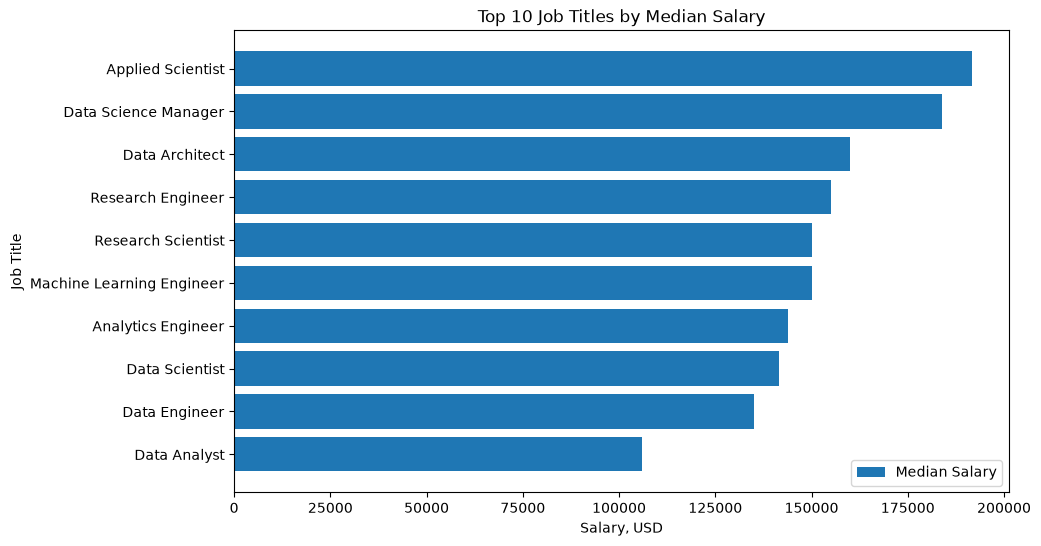

In [16]:
df = pd.read_csv("Data Science Salary 2021 to 2023.csv")
count_jobs = df["job_title"].value_counts()
first_ten = count_jobs.head(10)
top_jobs = first_ten.index

mask = df["job_title"].isin(top_jobs)
top_df = df[mask]
median_salary = top_df.groupby("job_title")["salary_in_usd"].median().sort_values()

JOBS_FIGSIZE = (10, 6)
fig, ax = plt.subplots(figsize=JOBS_FIGSIZE)
ax.barh(median_salary.index, median_salary.values, label="Median Salary")
ax.set_xlabel("Salary, USD")
ax.set_ylabel("Job Title")
ax.set_title("Top 10 Job Titles by Median Salary")
ax.legend()
plt.show()


**Выводы:**
- Самые высокооплачиваемые роли — исследовательские и управленческие:
  Applied Scientist, Data Science Manager, Data Architect.
- Самые низкооплачиваемые среди топ-10 — массовые прикладные роли:
  Data Analyst и Data Engineer.
- Зарплата растёт в сторону R&D и старших ролей: чисто аналитические
  должности оплачиваются ниже, чем исследования, архитектура и управление.
- Разрыв между верхней и нижней должностью ~80 тыс. USD — значит, сама
  должность сильно влияет на оплату.

## График 2. Медианная зарплата по должностям и уровням опыта

**Что визуализировано:** тепловая карта (heatmap) медианной зарплаты
(`salary_in_usd`) для топ-10 должностей в разрезе уровней опыта
(EN → MI → SE → EX). Строки — должности, столбцы — уровни, цвет и число
в клетке — медианная зарплата. Чем темнее клетка, тем выше зарплата.

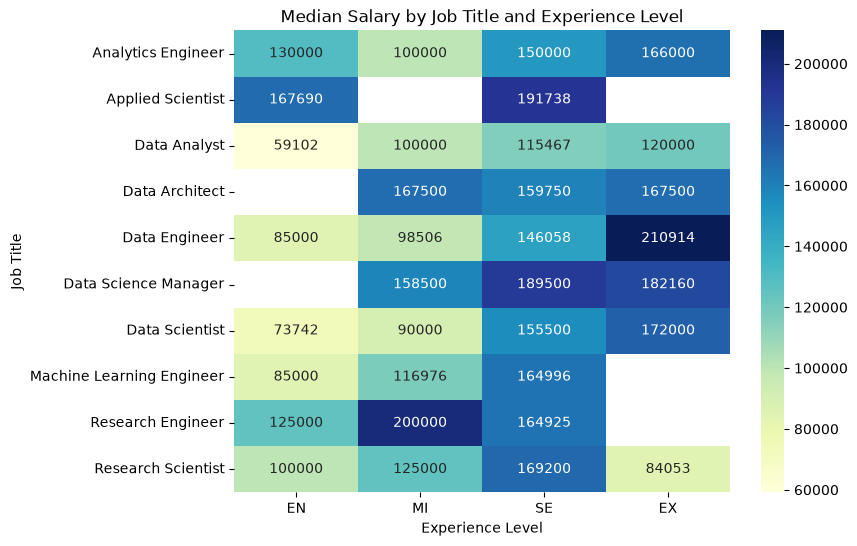

In [17]:
salary_pivot = top_df.pivot_table(
    index="job_title",
    columns="experience_level",
    values="salary_in_usd",
    aggfunc="median"
)

LEVEL_ORDER = ["EN", "MI", "SE", "EX"]
salary_pivot = salary_pivot[LEVEL_ORDER]

HEATMAP_FIGSIZE = (8, 6)

fig, ax = plt.subplots(figsize=HEATMAP_FIGSIZE)
sns.heatmap(salary_pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax)
ax.set_xlabel("Experience Level")
ax.set_ylabel("Job Title")
ax.set_title("Median Salary by Job Title and Experience Level")
plt.show()


**Выводы:**
- В целом зарплата растёт с опытом: по большинству должностей клетки
  темнеют слева направо (EN самый светлый, SE/EX — тёмные).
- Наибольший рост даёт переход от начального уровня (EN) к старшему (SE):
  разница часто вдвое и более.
- Пустые клетки — сочетания «должность + уровень», которых нет в данных.
- Отдельные аномалии, где EX оплачивается ниже SE (например, Research
  Scientist, Data Science Manager), связаны с малым числом записей на
  уровне EX — медиана по 1–2 значениям неустойчива, доверять таким
  клеткам нельзя.

## График 3. Медианная зарплата по странам
**Что визуализировано:** медианная зарплата (`salary_in_usd`) по топ-10
странам с наибольшим числом записей (`company_location`). Столбчатый график,
отсортирован по возрастанию. Взяты только топ-10 стран по количеству данных,
чтобы медиана была устойчивой и не искажалась странами с 1–2 записями.

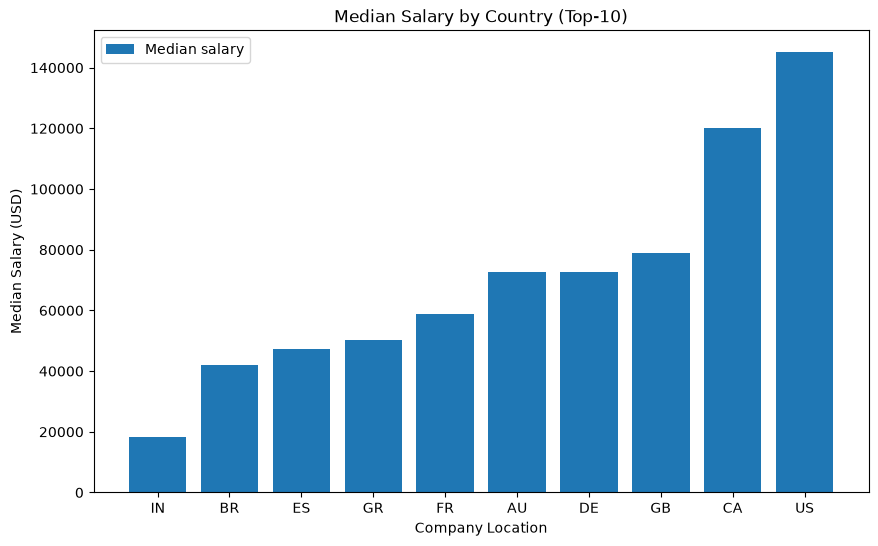

In [19]:
top_countries = df["company_location"].value_counts().head(10).index
mask = df["company_location"].isin(top_countries)
median_salary_country = df[mask].groupby("company_location")["salary_in_usd"].median().sort_values()

PLOT_FIGSIZE = (10, 6)
fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
ax.bar(median_salary_country.index, median_salary_country.values, label="Median salary")
ax.set_xlabel("Company Location")
ax.set_ylabel("Median Salary (USD)")
ax.set_title("Median Salary by Country (Top-10)")
ax.legend()
plt.show()

**Выводы:**
- Разброс зарплат между странами очень большой — ведущая страна платит
  в несколько раз больше, чем страны в нижней части графика.
- США (US) — самый частый работодатель в данных и одна из самых
  высокооплачиваемых стран.
- Страна оказывает сильное влияние на зарплату: даже при одинаковой
  должности медиана сильно зависит от расположения компании.
- Ограничение: данные сильно смещены в сторону США (большинство записей),
  поэтому выводы по другим странам менее надёжны.
  